In [18]:
import sys
import pandas as pd
import matplotlib.pyplot as plt

print("Python environment:", sys.executable)
print("Ready for data inspection.")

Python environment: /home/samuel-logan/uni/ENGG2112/lake-erie-forecast/.venv/bin/python
Ready for data inspection.


In [19]:
# IMPORTS AND DOWNLOADS
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

data_folder = Path("data/raw")
data_folder.mkdir(parents=True, exist_ok=True)

file_path = data_folder / "gibraltar_buoy.csv"

url = (
    "https://seagull-erddap.glos.org/erddap/tabledap/OSUGI_archive.csv?"
    "time,chlorophyll_fluorescence,phycocyanin_fluorescence,"
    "chlorophyll_fluorescence_aggregate_test,"
    "phycocyanin_fluorescence_aggregate_test"
)

if not file_path.exists():
    print("Downloading buoy data...")
    urlretrieve(url, file_path)

# The second CSV line contains units rather than measurements.
df = pd.read_csv(file_path, skiprows=[1])

print("Reading from:", file_path.resolve())
print("Raw rows:", len(df))
display(df.head())

Reading from: /home/samuel-logan/uni/ENGG2112/lake-erie-forecast/data/raw/gibraltar_buoy.csv
Raw rows: 130300


,time,chlorophyll_fluorescence,phycocyanin_fluorescence,chlorophyll_fluorescence_aggregate_test,phycocyanin_fluorescence_aggregate_test
0,2015-05-26T15:30:00Z,-999.0,NaN,NaN,NaN
1,2015-05-26T15:30:00Z,-999.0,NaN,NaN,NaN
2,2015-05-26T15:30:00Z,0.2,NaN,2.0,NaN
3,2015-05-26T16:00:00Z,-999.0,NaN,NaN,NaN
4,2015-05-26T16:00:00Z,-999.0,NaN,NaN,NaN


In [20]:
# Clean Individual Phycocyanin readings
working = df.copy()
working["time"] = pd.to_datetime(working["time"], utc=True)

keep = (
    working["phycocyanin_fluorescence"].between(-2, 100)
    & working["phycocyanin_fluorescence_aggregate_test"].isin([1, 2])
)

working = working.loc[keep].sort_values("time").copy()

print("Retained readings:", len(working))
print("Repeated timestamps:", working["time"].duplicated().sum())

assert working["time"].is_unique, (
    "Repeated timestamps found. Inspect these before continuing."
)

Retained readings: 66092
Repeated timestamps: 0


Accepted daily observations: 893


,accepted_days
day,
2015,64
2016,69
2017,109
2018,108
2019,53
2020,61
2021,126
2022,184
2023,119


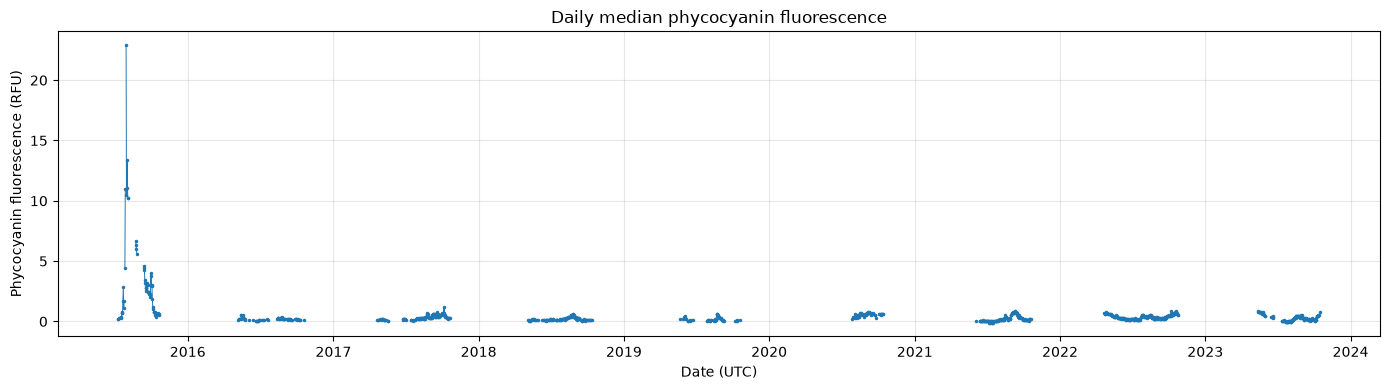

In [21]:
# Creating the cleaned daily series
working["day"] = working["time"].dt.floor("D")
working["hour"] = working["time"].dt.hour

daily = working.groupby("day").agg(
    phycocyanin_median=("phycocyanin_fluorescence", "median"),
    reading_count=("phycocyanin_fluorescence", "size"),
    hours_covered=("hour", "nunique"),
)

raw_times = pd.to_datetime(df["time"], utc=True)

calendar = pd.date_range(
    start=raw_times.min().floor("D"),
    end=raw_times.max().floor("D"),
    freq="D",
)

daily = daily.reindex(calendar)
daily.index.name = "day"

count_columns = ["reading_count", "hours_covered"]
daily[count_columns] = daily[count_columns].fillna(0).astype(int)

daily["coverage_ok"] = daily["hours_covered"] >= 12

daily["phycocyanin_daily"] = daily["phycocyanin_median"].where(
    daily["coverage_ok"]
)

print("Accepted daily observations:",
      daily["phycocyanin_daily"].notna().sum())

display(
    daily.groupby(daily.index.year)
    .agg(accepted_days=("coverage_ok", "sum"))
)

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(
    daily.index,
    daily["phycocyanin_daily"],
    marker=".",
    markersize=3,
    linewidth=0.7,
)
ax.set(
    title="Daily median phycocyanin fluorescence",
    xlabel="Date (UTC)",
    ylabel="Phycocyanin fluorescence (RFU)",
)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
# Create future targets and chronological splits
pair_check = daily[["phycocyanin_daily"]].copy()
splits = {}

train_end = pd.Timestamp("2022-01-01", tz="UTC")
validation_end = pd.Timestamp("2023-01-01", tz="UTC")
test_end = pd.Timestamp("2024-01-01", tz="UTC")

for horizon in [3, 7]:
    target_column = f"target_{horizon}d"

    pair_check[target_column] = (
        pair_check["phycocyanin_daily"].shift(-horizon)
    )

    examples = pair_check[
        ["phycocyanin_daily", target_column]
    ].dropna().copy()

    examples.columns = ["today", "target"]
    examples["target_date"] = (
        examples.index + pd.Timedelta(days=horizon)
    )

    # Both the input date and target date must belong to the period.
    splits[horizon] = {
        "train": examples.loc[
            (examples.index < train_end)
            & (examples["target_date"] < train_end)
        ].copy(),

        "validation": examples.loc[
            (examples.index >= train_end)
            & (examples.index < validation_end)
            & (examples["target_date"] < validation_end)
        ].copy(),

        "test": examples.loc[
            (examples.index >= validation_end)
            & (examples.index < test_end)
            & (examples["target_date"] < test_end)
        ].copy(),
    }

split_counts = pd.DataFrame({
    f"{horizon}-day": {
        name: len(table)
        for name, table in partitions.items()
    }
    for horizon, partitions in splits.items()
})

display(split_counts)

,3-day,7-day
train,442,415
validation,178,175
test,110,99


In [23]:
# Evaluate the persistence baseline with scikit-learn

baseline_rows = []

for horizon in [3, 7]:
    validation = splits[horizon]["validation"]

    actual = validation["target"]
    predicted = validation["today"]

    baseline_rows.append({
        "horizon_days": horizon,
        "examples": len(validation),
        "MAE_RFU": mean_absolute_error(actual, predicted),
        "RMSE_RFU": mean_squared_error(actual, predicted) ** 0.5,
    })

baseline_results = pd.DataFrame(baseline_rows)
display(baseline_results.round(4))

,horizon_days,examples,MAE_RFU,RMSE_RFU
0,3,178,0.0721,0.0982
1,7,175,0.0897,0.1229


In [24]:
# Building Historical Features
signal = daily["phycocyanin_daily"].sort_index()

features = pd.DataFrame(index=signal.index)

features["today_rfu"] = signal
features["yesterday_rfu"] = signal.shift(1)

# Trailing windows include today.
features["mean_3d"] = signal.rolling(
    window=3, min_periods=2
).mean()

features["mean_7d"] = signal.rolling(
    window=7, min_periods=4
).mean()

# Number of available daily values in each window.
features["count_3d"] = signal.rolling(
    window=3, min_periods=1
).count()

features["count_7d"] = signal.rolling(
    window=7, min_periods=1
).count()

features["change_1d"] = signal - signal.shift(1)

# Seasonal encoding: places the end and start of the year close together.
days_in_year = np.where(features.index.is_leap_year, 366, 365)

season_angle = (
    2 * np.pi * (features.index.dayofyear - 1) / days_in_year
)

features["season_sin"] = np.sin(season_angle)
features["season_cos"] = np.cos(season_angle)

# Attach input tables X and target columns y to the existing splits.
model_data = {}

for horizon in [3, 7]:
    model_data[horizon] = {}

    for partition in ["train", "validation", "test"]:
        examples = splits[horizon][partition]

        model_data[horizon][partition] = {
            "X": features.loc[examples.index].copy(),
            "y": examples["target"].copy(),
        }

X_train = model_data[3]["train"]["X"]

display(X_train.head(10).round(3))

print("Missing feature values in the 3-day training data:")
display(X_train.isna().sum())


,today_rfu,yesterday_rfu,mean_3d,mean_7d,count_3d,count_7d,change_1d,season_sin,season_cos
day,,,,,,,,,
2015-07-17 00:00:00+00:00,0.4,NaN,NaN,NaN,1.0,2.0,NaN,-0.247,-0.969
2015-07-18 00:00:00+00:00,0.3,0.40,0.350,NaN,2.0,2.0,-0.10,-0.264,-0.965
2015-07-19 00:00:00+00:00,0.8,0.30,0.500,NaN,3.0,3.0,0.50,-0.280,-0.960
2015-07-20 00:00:00+00:00,0.7,0.80,0.600,0.550,3.0,4.0,-0.10,-0.297,-0.955
2015-07-21 00:00:00+00:00,0.7,0.70,0.733,0.580,3.0,5.0,0.00,-0.313,-0.950
2015-07-22 00:00:00+00:00,1.7,0.70,1.033,0.767,3.0,6.0,1.00,-0.329,-0.944
2015-07-24 00:00:00+00:00,1.1,2.85,1.883,1.164,3.0,7.0,-1.75,-0.362,-0.932
2015-07-25 00:00:00+00:00,1.7,1.10,1.883,1.364,3.0,7.0,0.60,-0.378,-0.926
2015-07-27 00:00:00+00:00,4.4,NaN,3.050,2.075,2.0,6.0,NaN,-0.409,-0.912


Missing feature values in the 3-day training data:


today_rfu         0
yesterday_rfu    61
mean_3d          29
mean_7d          50
count_3d          0
count_7d          0
change_1d        61
season_sin        0
season_cos        0
dtype: int64

In [ ]:
# training first models, comparing them with the baseline on 2022
# S
from sklearn.ensemble import HistGradientBoostingRegressor

models = {}
validation_predictions = {}
results = []

for horizon in [3, 7]:
    train = model_data[horizon]["train"]
    validation = model_data[horizon]["validation"]

    model = HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_iter=100,
        max_leaf_nodes=7,
        min_samples_leaf=20,
        early_stopping=False,
        random_state=42,
    )

    # Learn from 2015–2021 inputs and their observed future targets.
    model.fit(train["X"], train["y"])

    # Predict 2022 targets using only the input features.
    predicted = model.predict(validation["X"])

    models[horizon] = model

    comparison = pd.DataFrame({
        "actual": validation["y"],
        "baseline": validation["X"]["today_rfu"],
        "model": predicted,
    })

    validation_predictions[horizon] = comparison

    # Evaluate both approaches on exactly the same dates.
    for approach in ["baseline", "model"]:
        results.append({
            "horizon_days": horizon,
            "approach": approach,
            "examples": len(comparison),
            "MAE_RFU": mean_absolute_error(
                comparison["actual"], comparison[approach]
            ),
            "RMSE_RFU": mean_squared_error(
                comparison["actual"], comparison[approach]
            ) ** 0.5,
        })

results = pd.DataFrame(results)
display(results.round(4))

,horizon_days,approach,examples,MAE_RFU,RMSE_RFU
0,3,baseline,178,0.0721,0.0982
1,3,model,178,0.2111,0.3159
2,7,baseline,175,0.0897,0.1229
3,7,model,175,0.6166,1.0807


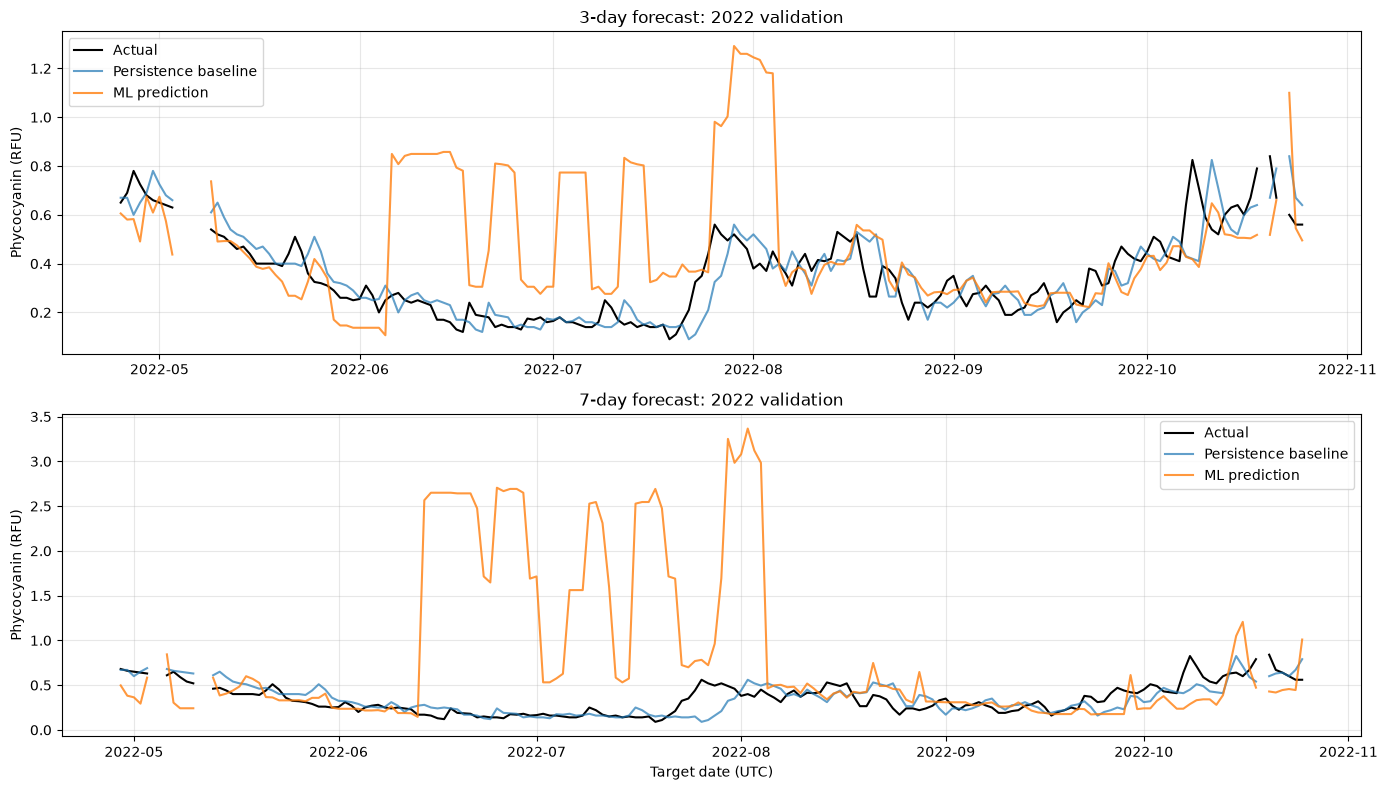


3-day forecast:


,actual,baseline,model
min,0.09,0.09,0.106
median,0.32,0.32,0.388
max,0.84,0.84,1.292


Mean prediction minus actual: 0.1258 RFU

7-day forecast:


,actual,baseline,model
min,0.09,0.090,0.145
median,0.32,0.320,0.426
max,0.84,0.825,3.366


Mean prediction minus actual: 0.4946 RFU


In [26]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

for ax, horizon in zip(axes, [3, 7]):
    comparison = validation_predictions[horizon].copy()

    # Display predictions against the date being forecast.
    comparison.index = (
        comparison.index + pd.Timedelta(days=horizon)
    )

    # Include missing dates so lines don't bridge gaps.
    comparison = comparison.asfreq("D")

    ax.plot(
        comparison.index, comparison["actual"],
        label="Actual", color="black", linewidth=1.5
    )
    ax.plot(
        comparison.index, comparison["baseline"],
        label="Persistence baseline", alpha=0.7
    )
    ax.plot(
        comparison.index, comparison["model"],
        label="ML prediction", alpha=0.8
    )

    ax.set_title(f"{horizon}-day forecast: 2022 validation")
    ax.set_ylabel("Phycocyanin (RFU)")
    ax.legend()
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Target date (UTC)")
plt.tight_layout()
plt.show()

# Numerical check alongside the plots.
for horizon in [3, 7]:
    comparison = validation_predictions[horizon]

    print(f"\n{horizon}-day forecast:")
    display(
        comparison.agg(["min", "median", "max"]).round(3)
    )

    print(
        "Mean prediction minus actual:",
        round((comparison["model"] - comparison["actual"]).mean(), 4),
        "RFU"
    )

In [27]:
from sklearn.base import clone

models_without_2015 = {}
predictions_without_2015 = {}
comparison_rows = []

for horizon in [3, 7]:
    train = model_data[horizon]["train"]
    validation = model_data[horizon]["validation"]

    # Retain only 2016–2021 training examples.
    keep = train["X"].index.year >= 2016
    X_train_reduced = train["X"].loc[keep]
    y_train_reduced = train["y"].loc[keep]

    # Copy the original settings, but start with an untrained model.
    comparison_model = clone(models[horizon])
    comparison_model.fit(X_train_reduced, y_train_reduced)

    predicted = comparison_model.predict(validation["X"])

    models_without_2015[horizon] = comparison_model
    predictions_without_2015[horizon] = pd.Series(
        predicted,
        index=validation["y"].index,
        name="without_2015",
    )

    predictions_to_compare = {
        "Persistence baseline": validation["X"]["today_rfu"],
        "Original: 2015–2021": (
            validation_predictions[horizon]["model"]
            .reindex(validation["y"].index)
        ),
        "Comparison: 2016–2021": predictions_without_2015[horizon],
    }

    for approach, prediction in predictions_to_compare.items():
        actual = validation["y"]

        comparison_rows.append({
            "horizon_days": horizon,
            "approach": approach,
            "validation_examples": len(actual),
            "MAE_RFU": mean_absolute_error(actual, prediction),
            "RMSE_RFU": mean_squared_error(actual, prediction) ** 0.5,
            "bias_RFU": (prediction - actual).mean(),
        })

    print(
        f"{horizon}-day model: training examples "
        f"{len(train['X'])} → {len(X_train_reduced)}"
    )

comparison_results = pd.DataFrame(comparison_rows)
display(comparison_results.round(4))

3-day model: training examples 442 → 391
7-day model: training examples 415 → 371


,horizon_days,approach,validation_examples,MAE_RFU,RMSE_RFU,bias_RFU
0,3,Persistence baseline,178,0.0721,0.0982,0.0012
1,3,Original: 2015–2021,178,0.2111,0.3159,0.1258
2,3,Comparison: 2016–2021,178,0.0736,0.1033,-0.0345
3,7,Persistence baseline,175,0.0897,0.1229,-0.0007
4,7,Original: 2015–2021,175,0.6166,1.0807,0.4946
5,7,Comparison: 2016–2021,175,0.1276,0.1608,-0.0705


In [28]:
models_absolute = {}
predictions_absolute = {}
absolute_rows = []

for horizon in [3, 7]:
    train = model_data[horizon]["train"]
    validation = model_data[horizon]["validation"]

    # Same original settings; change only the training loss.
    model = clone(models[horizon])
    model.set_params(loss="absolute_error")

    model.fit(train["X"], train["y"])

    prediction = pd.Series(
        model.predict(validation["X"]),
        index=validation["y"].index,
        name="absolute_error_model",
    )

    models_absolute[horizon] = model
    predictions_absolute[horizon] = prediction

    actual = validation["y"]

    absolute_rows.append({
        "horizon_days": horizon,
        "approach": "Absolute loss: 2015–2021",
        "validation_examples": len(actual),
        "MAE_RFU": mean_absolute_error(actual, prediction),
        "RMSE_RFU": mean_squared_error(actual, prediction) ** 0.5,
        "bias_RFU": (prediction - actual).mean(),
    })

# Show this experiment alongside the previous results.
loss_comparison = pd.concat(
    [comparison_results, pd.DataFrame(absolute_rows)],
    ignore_index=True,
).sort_values("horizon_days", kind="stable")

display(loss_comparison.round(4))

,horizon_days,approach,validation_examples,MAE_RFU,RMSE_RFU,bias_RFU
0,3,Persistence baseline,178,0.0721,0.0982,0.0012
1,3,Original: 2015–2021,178,0.2111,0.3159,0.1258
2,3,Comparison: 2016–2021,178,0.0736,0.1033,-0.0345
6,3,Absolute loss: 2015–2021,178,0.0727,0.1029,-0.0159
3,7,Persistence baseline,175,0.0897,0.1229,-0.0007
4,7,Original: 2015–2021,175,0.6166,1.0807,0.4946
5,7,Comparison: 2016–2021,175,0.1276,0.1608,-0.0705
7,7,Absolute loss: 2015–2021,175,0.1203,0.1534,-0.0684


In [29]:
# Clean chlorophyll independently from phycocyanin.
chlorophyll = df.copy()
chlorophyll["time"] = pd.to_datetime(chlorophyll["time"], utc=True)

keep = (
    chlorophyll["chlorophyll_fluorescence"].between(-2, 100)
    & chlorophyll["chlorophyll_fluorescence_aggregate_test"].isin([1, 2])
)

chlorophyll = chlorophyll.loc[keep].sort_values("time").copy()

print("Retained chlorophyll readings:", len(chlorophyll))
print("Repeated timestamps:", chlorophyll["time"].duplicated().sum())

# Investigate any repeated timestamps before aggregating.
assert chlorophyll["time"].is_unique, (
    "Repeated chlorophyll timestamps found. Send me the counts "
    "before continuing."
)

chlorophyll["day"] = chlorophyll["time"].dt.floor("D")
chlorophyll["hour"] = chlorophyll["time"].dt.hour

chlorophyll_daily = chlorophyll.groupby("day").agg(
    median_rfu=("chlorophyll_fluorescence", "median"),
    hours_covered=("hour", "nunique"),
)

# Align with the same complete calendar as our target.
chlorophyll_daily = chlorophyll_daily.reindex(daily.index)

chlorophyll_daily["chlorophyll_daily"] = (
    chlorophyll_daily["median_rfu"].where(
        chlorophyll_daily["hours_covered"] >= 12
    )
)

# Check availability and scale by year.
chlorophyll_summary = (
    chlorophyll_daily["chlorophyll_daily"]
    .groupby(chlorophyll_daily.index.year)
    .agg(
        accepted_days="count",
        minimum="min",
        median="median",
        maximum="max",
    )
)

display(chlorophyll_summary.round(3))

# How often is today's chlorophyll available on our validation dates?
for horizon in [3, 7]:
    dates = model_data[horizon]["validation"]["X"].index

    available = (
        chlorophyll_daily.loc[dates, "chlorophyll_daily"]
        .notna()
        .sum()
    )

    print(
        f"{horizon}-day validation: chlorophyll available "
        f"on {available} of {len(dates)} input days"
    )

Retained chlorophyll readings: 80817
Repeated timestamps: 0


,accepted_days,minimum,median,maximum
day,,,,
2015,109,0.20,0.800,2.20
2016,140,0.10,0.500,4.40
2017,143,0.00,0.500,1.60
2018,150,0.00,0.400,0.90
2019,62,0.00,0.300,0.65
2020,72,0.30,0.800,1.50
2021,126,-0.20,0.400,1.50
2022,184,0.20,0.472,1.14
2023,119,0.19,0.665,1.95


3-day validation: chlorophyll available on 178 of 178 input days
7-day validation: chlorophyll available on 175 of 175 input days


In [30]:
# Preserve the original feature table.
features_with_chlorophyll = features.copy()

chl = chlorophyll_daily["chlorophyll_daily"]

features_with_chlorophyll["chl_today"] = chl
features_with_chlorophyll["chl_yesterday"] = chl.shift(1)

features_with_chlorophyll["chl_mean_3d"] = (
    chl.rolling(window=3, min_periods=2).mean()
)
features_with_chlorophyll["chl_mean_7d"] = (
    chl.rolling(window=7, min_periods=4).mean()
)

features_with_chlorophyll["chl_count_3d"] = (
    chl.rolling(window=3, min_periods=1).count()
)
features_with_chlorophyll["chl_count_7d"] = (
    chl.rolling(window=7, min_periods=1).count()
)

features_with_chlorophyll["chl_change_1d"] = chl - chl.shift(1)

# Inspect missing chlorophyll inputs in training and validation.
chl_columns = [
    column for column in features_with_chlorophyll.columns
    if column.startswith("chl_")
]

missing_summary = {}

for partition in ["train", "validation"]:
    dates = model_data[3][partition]["X"].index
    missing_summary[partition] = (
        features_with_chlorophyll.loc[dates, chl_columns]
        .isna()
        .sum()
    )

display(pd.DataFrame(missing_summary))

,train,validation
chl_today,13,0
chl_yesterday,25,3
chl_mean_3d,17,2
chl_mean_7d,25,3
chl_count_3d,0,0
chl_count_7d,0,0
chl_change_1d,32,3


In [31]:
models_with_chlorophyll = {}
predictions_with_chlorophyll = {}
chlorophyll_results = []

for horizon in [3, 7]:
    train = model_data[horizon]["train"]
    validation = model_data[horizon]["validation"]

    # Same example dates and targets; expanded input columns.
    X_train = features_with_chlorophyll.loc[train["X"].index]
    X_validation = features_with_chlorophyll.loc[validation["X"].index]

    model = clone(models_absolute[horizon])
    model.fit(X_train, train["y"])

    prediction = pd.Series(
        model.predict(X_validation),
        index=validation["y"].index,
    )

    models_with_chlorophyll[horizon] = model
    predictions_with_chlorophyll[horizon] = prediction

    approaches = {
        "Persistence": validation["X"]["today_rfu"],
        "Phycocyanin history": predictions_absolute[horizon],
        "History + chlorophyll": prediction,
    }

    for approach, predicted in approaches.items():
        actual = validation["y"]
        predicted = predicted.reindex(actual.index)

        chlorophyll_results.append({
            "horizon_days": horizon,
            "approach": approach,
            "examples": len(actual),
            "MAE_RFU": mean_absolute_error(actual, predicted),
            "RMSE_RFU": mean_squared_error(actual, predicted) ** 0.5,
            "bias_RFU": (predicted - actual).mean(),
        })

chlorophyll_results = pd.DataFrame(chlorophyll_results)
display(chlorophyll_results.round(4))

,horizon_days,approach,examples,MAE_RFU,RMSE_RFU,bias_RFU
0,3,Persistence,178,0.0721,0.0982,0.0012
1,3,Phycocyanin history,178,0.0727,0.1029,-0.0159
2,3,History + chlorophyll,178,0.0793,0.1055,-0.0045
3,7,Persistence,175,0.0897,0.1229,-0.0007
4,7,Phycocyanin history,175,0.1203,0.1534,-0.0684
5,7,History + chlorophyll,175,0.1187,0.1511,-0.0555


In [32]:
weather_path = data_folder / "toledo_weather_2013_2024.csv"

weather_url = (
    "https://www.ncei.noaa.gov/access/services/data/v1?"
    "dataset=daily-summaries"
    "&stations=USW00094830"
    "&startDate=2013-01-01"
    "&endDate=2024-12-31"
    "&dataTypes=TMAX,TMIN,PRCP,AWND"
    "&format=csv"
    "&units=metric"
    "&includeAttributes=true"
)

if not weather_path.exists():
    print("Downloading weather data...")
    urlretrieve(weather_url, weather_path)

weather_raw = pd.read_csv(weather_path)

print("File:", weather_path.resolve())
print("Rows:", len(weather_raw))
print("Columns:", weather_raw.columns.tolist())

display(weather_raw.head())

weather_variables = ["TMAX", "TMIN", "PRCP", "AWND"]

# Report availability without filling or filtering observations.
weather_values = weather_raw.reindex(
    columns=weather_variables
).apply(pd.to_numeric, errors="coerce")

display(pd.DataFrame({
    "present": weather_values.notna().sum(),
    "missing": weather_values.isna().sum(),
}))

# Inspect the accompanying measurement/quality attributes.
for column in weather_raw.columns:
    if column.endswith("_ATTRIBUTES"):
        print(f"\n{column}")
        print(weather_raw[column].value_counts(dropna=False).head(10))

File: /home/samuel-logan/uni/ENGG2112/lake-erie-forecast/data/raw/toledo_weather_2013_2024.csv
Rows: 4383
Columns: ['STATION', 'DATE', 'AWND', 'AWND_ATTRIBUTES', 'PRCP', 'PRCP_ATTRIBUTES', 'TMAX', 'TMAX_ATTRIBUTES', 'TMIN', 'TMIN_ATTRIBUTES']


,STATION,DATE,AWND,AWND_ATTRIBUTES,PRCP,PRCP_ATTRIBUTES,TMAX,TMAX_ATTRIBUTES,TMIN,TMIN_ATTRIBUTES
0,USW00094830,2013-01-01,2.3,",,X",0.0,",,X,2400",-0.6,",,X",-12.8,",,X"
1,USW00094830,2013-01-02,2.9,",,X",0.0,",,X,2400",-5.0,",,X",-13.9,",,X"
2,USW00094830,2013-01-03,4.8,",,X",0.0,",,X,2400",-2.2,",,X",-12.8,",,X"
3,USW00094830,2013-01-04,7.6,",,X",0.0,",,X,2400",-2.2,",,X",-7.2,",,X"
4,USW00094830,2013-01-05,3.5,",,X",0.0,"T,,X,2400",0.6,",,X",-7.2,",,X"


,present,missing
TMAX,4361,22
TMIN,4360,23
PRCP,4360,23
AWND,4360,23



AWND_ATTRIBUTES
AWND_ATTRIBUTES
,,W    4269
,,X      90
NaN      23
,,1       1
Name: count, dtype: int64

PRCP_ATTRIBUTES
PRCP_ATTRIBUTES
,,W,2400     3678
T,,W,2400     592
,,X,2400       61
T,,X,2400      29
NaN            23
Name: count, dtype: int64

TMAX_ATTRIBUTES
TMAX_ATTRIBUTES
,,W    4271
,,X      90
NaN      22
Name: count, dtype: int64

TMIN_ATTRIBUTES
TMIN_ATTRIBUTES
,,W    4270
,,X      90
NaN      23
Name: count, dtype: int64


In [ ]:
# Clean Individual Phycocyanin readings
working = df.copy()
working["time"] = pd.to_datetime(working["time"], utc=True)

keep = (
    working["phycocyanin_fluorescence"].between(-2, 100)
    & working["phycocyanin_fluorescence_aggregate_test"].isin([1, 2])
)

working = working.loc[keep].sort_values("time").copy()

print("Retained readings:", len(working))
print("Repeated timestamps:", working["time"].duplicated().sum())

assert working["time"].is_unique, (
    "Repeated timestamps found. Inspect these before continuing."
)

Retained readings: 66092
Repeated timestamps: 0


In [33]:
weather = weather_raw.copy()
weather["DATE"] = pd.to_datetime(weather["DATE"], utc=True)
weather = weather.set_index("DATE").sort_index()

assert weather.index.is_unique, "Repeated weather dates need inspection."

variables = ["TMAX", "TMIN", "PRCP", "AWND"]

for variable in variables:
    weather[variable] = pd.to_numeric(
        weather[variable], errors="coerce"
    )

    # Attributes: measurement flag, quality flag, source, optional time.
    attributes = weather[f"{variable}_ATTRIBUTES"].astype("string")
    quality_flag = attributes.str.split(",").str[1].str.strip()

    # Retain measurements with a recorded blank quality flag.
    quality_ok = quality_flag.eq("").fillna(False)
    weather.loc[~quality_ok, variable] = np.nan

# Complete calendar makes shifts and windows use calendar days.
weather = weather.reindex(
    pd.date_range(
        weather.index.min(),
        weather.index.max(),
        freq="D",
        tz="UTC",
    )
)

weather_features = pd.DataFrame(index=weather.index)

weather_features["weather_tmax_lag2"] = weather["TMAX"].shift(2)
weather_features["weather_tmin_lag2"] = weather["TMIN"].shift(2)
weather_features["weather_wind_lag2"] = weather["AWND"].shift(2)

# Require every rainfall value in the window.
weather_features["weather_rain_3d_lag2"] = (
    weather["PRCP"].rolling(3, min_periods=3).sum().shift(2)
)
weather_features["weather_rain_7d_lag2"] = (
    weather["PRCP"].rolling(7, min_periods=7).sum().shift(2)
)

# Add weather to phycocyanin history, without chlorophyll.
features_with_weather = features.join(weather_features)

weather_columns = weather_features.columns.tolist()

print("Missing weather inputs on validation dates:")
display(pd.DataFrame({
    f"{horizon}-day": (
        features_with_weather.loc[
            model_data[horizon]["validation"]["X"].index,
            weather_columns,
        ].isna().sum()
    )
    for horizon in [3, 7]
}))

Missing weather inputs on validation dates:


,3-day,7-day
weather_tmax_lag2,0,0
weather_tmin_lag2,0,0
weather_wind_lag2,0,0
weather_rain_3d_lag2,0,0
weather_rain_7d_lag2,0,0


In [35]:
models_with_weather = {}
predictions_with_weather = {}
weather_rows = []

for horizon in [3, 7]:
    train = model_data[horizon]["train"]
    validation = model_data[horizon]["validation"]

    X_train = features_with_weather.loc[train["X"].index]
    X_validation = features_with_weather.loc[validation["X"].index]

    model = clone(models_absolute[horizon])
    model.fit(X_train, train["y"])

    prediction = pd.Series(
        model.predict(X_validation),
        index=validation["y"].index,
    )

    models_with_weather[horizon] = model
    predictions_with_weather[horizon] = prediction

    approaches = {
        "Persistence": validation["X"]["today_rfu"],
        "Phycocyanin history": predictions_absolute[horizon],
        "History + weather": prediction,
    }

    for approach, predicted in approaches.items():
        actual = validation["y"]
        predicted = predicted.reindex(actual.index)

        weather_rows.append({
            "horizon_days": horizon,
            "approach": approach,
            "examples": len(actual),
            "MAE_RFU": mean_absolute_error(actual, predicted),
            "RMSE_RFU": mean_squared_error(actual, predicted) ** 0.5,
            "bias_RFU": (predicted - actual).mean(),
        })

weather_results = pd.DataFrame(weather_rows)
display(weather_results.round(4))

,horizon_days,approach,examples,MAE_RFU,RMSE_RFU,bias_RFU
0,3,Persistence,178,0.0721,0.0982,0.0012
1,3,Phycocyanin history,178,0.0727,0.1029,-0.0159
2,3,History + weather,178,0.0794,0.1041,-0.0054
3,7,Persistence,175,0.0897,0.1229,-0.0007
4,7,Phycocyanin history,175,0.1203,0.1534,-0.0684
5,7,History + weather,175,0.1151,0.1520,-0.0602


In [36]:
final_models = {}
test_predictions = {}
test_rows = []

test_start = pd.Timestamp("2023-01-01", tz="UTC")

for horizon in [3, 7]:
    # Use the feature set and settings selected using 2022.
    if horizon == 3:
        selected_features = features
        selected_model = models_absolute[horizon]
        model_label = "History ML"
    else:
        selected_features = features_with_weather
        selected_model = models_with_weather[horizon]
        model_label = "History + weather ML"

    # Combine the existing training and validation examples.
    development = pd.concat([
        splits[horizon]["train"],
        splits[horizon]["validation"],
    ]).sort_index()

    test = splits[horizon]["test"]

    # Ensure no 2023 target enters training.
    assert (development["target_date"] < test_start).all()
    assert development.index.intersection(test.index).empty

    X_development = selected_features.loc[development.index]
    y_development = development["target"]
    X_test = selected_features.loc[test.index]

    # Same settings, freshly trained on 2015–2022.
    final_model = clone(selected_model)
    final_model.fit(X_development, y_development)

    final_models[horizon] = final_model

    comparison = pd.DataFrame({
        "target_date": test["target_date"],
        "actual": test["target"],
        "baseline": test["today"],
        "model": final_model.predict(X_test),
    })

    test_predictions[horizon] = comparison

    for column, label in [
        ("baseline", "Persistence"),
        ("model", model_label),
    ]:
        actual = comparison["actual"]
        predicted = comparison[column]

        test_rows.append({
            "horizon_days": horizon,
            "approach": label,
            "test_examples": len(comparison),
            "MAE_RFU": mean_absolute_error(actual, predicted),
            "RMSE_RFU": mean_squared_error(actual, predicted) ** 0.5,
            "bias_RFU": (predicted - actual).mean(),
        })

    print(
        f"{horizon}-day model: "
        f"{len(development)} development examples, "
        f"{len(test)} test examples"
    )

final_test_results = pd.DataFrame(test_rows)
display(final_test_results.round(4))

3-day model: 620 development examples, 110 test examples
7-day model: 590 development examples, 99 test examples


,horizon_days,approach,test_examples,MAE_RFU,RMSE_RFU,bias_RFU
0,3,Persistence,110,0.0845,0.1092,-0.0045
1,3,History ML,110,0.0852,0.1092,0.0022
2,7,Persistence,99,0.1305,0.1671,-0.0175
3,7,History + weather ML,99,0.1125,0.1476,-0.0011
